# Laboratorio 25. MNIST: cargar y utilizar un modelo entrenado
**Asignatura:** Analítica de Datos  
**Docente:** Luis Miguel Gómez Meneses  
**Institución:** Universidad Cooperativa de Colombia  
**Programa:** Ingeniería de Software — Séptimo semestre  
**Clase 12 — 6 de noviembre de 2026**  
**Duración orientativa:** 50 minutos
En el laboratorio 24 comparamos hiperparámetros y guardamos un modelo.
Ahora utilizaremos ese mismo modelo para reconocer dígitos mediante una interfaz.
**No volveremos a entrenar la red.**

Al terminar podrás cargar un archivo `.keras`, preparar una imagen, obtener una
predicción y explicar qué hace la interfaz y qué hace el modelo.


## Antes de comenzar
1. Descarga del laboratorio 24 el archivo **`Laboratorio_24_MNIST_resultados.zip`**.
2. Abre este notebook en una sesión nueva de Google Colab.
3. Ejecuta las celdas en orden. La CPU es suficiente; no necesitas activar GPU.
4. En el paso 2 sube el ZIP completo, sin descomprimirlo en tu computador.

El ZIP contiene `modelo_mnist.keras`, la configuración y diez ejemplos de MNIST.
**No debes subir el archivo `.ipynb` del laboratorio 24 en lugar del ZIP.**
Si aún no tienes el ZIP, ejecuta las últimas celdas de aquel laboratorio.

| Actividad | Tiempo |
|---|---:|
| Preparar el entorno, subir el ZIP y cargar el modelo | 10 min |
| Realizar e interpretar predicciones con MNIST | 10 min |
| Preparar imágenes propias y analizar su efecto | 10 min |
| Utilizar la interfaz y registrar observaciones | 15 min |
| Guardar resultados y redactar conclusiones | 5 min |

La interfaz será una demostración temporal: en Colab se genera un enlace
accesible para quien lo tenga y funciona mientras la sesión y el servidor estén activos.


## 1. Librerías y entorno
Usaremos **TensorFlow/Keras** para cargar la red; **NumPy** para los arreglos;
**Pillow** para preparar imágenes; **Matplotlib** para visualizar resultados;
**pandas** para las tablas y **Gradio** para la interfaz.

La siguiente celda instala los paquetes que faltan y utiliza Gradio 6.31.0.
No cambia una instalación existente de TensorFlow. Si Colab solicita reiniciar
la sesión después de instalar, reiníciala y vuelve a ejecutar desde aquí.


In [1]:
import importlib.util
import importlib.metadata
import subprocess
import sys
dependencias = {
    "tensorflow": "tensorflow>=2.16,<3", "numpy": "numpy",
    "pandas": "pandas", "matplotlib": "matplotlib", "PIL": "Pillow>=10"
}
faltantes = [paquete for modulo, paquete in dependencias.items()
             if importlib.util.find_spec(modulo) is None]
try:
    version_gradio = importlib.metadata.version("gradio")
except importlib.metadata.PackageNotFoundError:
    version_gradio = "0"
if version_gradio != "6.31.0":
    faltantes.append("gradio==6.31.0")
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Dependencias disponibles.")

Dependencias disponibles.


In [2]:
import os
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"
import json
import shutil
import zipfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import tensorflow as tf
import gradio as gr
from IPython.display import display, FileLink

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

ID_SESION = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
CARPETA = Path("laboratorio25_mnist") / ID_SESION
CARPETA.mkdir(parents=True, exist_ok=True)
ENTRADA = CARPETA / "archivos_lab24"
SALIDA = CARPETA / "resultados_lab25"
ENTRADA.mkdir(exist_ok=True)
SALIDA.mkdir(exist_ok=True)

print("TensorFlow:", tf.__version__, "| Gradio:", gr.__version__)
print("Carpeta de esta ejecución:", CARPETA.resolve())


TensorFlow: 2.21.0 | Gradio: 6.31.0
Carpeta de esta ejecución: /content/laboratorio25_mnist/20261106_204421_310834


## 2. Subir el ZIP del laboratorio 24
Ejecuta esta celda y selecciona **un solo ZIP**. Si ya lo subiste mediante el panel
de archivos de Colab, puedes escribir su ruta en `RUTA_ZIP`.
Fuera de Colab debes indicar la ruta del archivo.

Solo reutilizamos el paquete exportado en el laboratorio anterior; aquí no hay
descarga de otra base de datos ni entrenamiento adicional.


In [3]:
RUTA_ZIP = "/content/Laboratorio_24_MNIST_resultados.zip"
if RUTA_ZIP:
    ruta_zip = Path(RUTA_ZIP)
elif EN_COLAB:
    subidos = files.upload()
    nombres_zip = [nombre for nombre in subidos if nombre.lower().endswith(".zip")]
    if len(nombres_zip) != 1:
        raise ValueError("Selecciona exactamente el ZIP de resultados del laboratorio 24.")
    nombre = nombres_zip[0]
    ruta_zip = CARPETA / Path(nombre).name
    ruta_zip.write_bytes(subidos[nombre])
else:
    raise ValueError("Escribe la ruta de tu ZIP en RUTA_ZIP y ejecuta otra vez esta celda.")

if not ruta_zip.is_file() or not zipfile.is_zipfile(ruta_zip):
    raise ValueError("No se encontró un ZIP válido en la ruta indicada.")

# Revisar las rutas antes de extraer y limitar el tamaño descomprimido.
with zipfile.ZipFile(ruta_zip) as paquete:
    if sum(info.file_size for info in paquete.infolist()) > 100 * 1024**2:
        raise ValueError("Este ZIP supera el tamaño esperado para el laboratorio (100 MB).")
    for info in paquete.infolist():
        destino = (ENTRADA / info.filename).resolve()
        if not destino.is_relative_to(ENTRADA.resolve()):
            raise ValueError("El ZIP contiene una ruta no válida.")
    paquete.extractall(ENTRADA)

modelos = list(ENTRADA.rglob("modelo_mnist.keras"))
if len(modelos) != 1:
    raise ValueError("El ZIP debe contener exactamente un modelo_mnist.keras.")
RUTA_MODELO = modelos[0]
BASE = RUTA_MODELO.parent
for nombre in ["configuracion_y_resultados.json", "ejemplos_mnist.npz"]:
    if not (BASE / nombre).is_file():
        raise FileNotFoundError(f"Falta {nombre}. Exporta nuevamente el ZIP del laboratorio 24.")
configuracion = json.loads((BASE / "configuracion_y_resultados.json").read_text(encoding="utf-8"))
print("Modelo encontrado:", RUTA_MODELO.name)
print("Dataset:", configuracion["dataset"])
print("Configuración elegida en el laboratorio 24:")
display(pd.DataFrame([configuracion["seleccion"]]))


Modelo encontrado: modelo_mnist.keras
Dataset: MNIST
Configuración elegida en el laboratorio 24:


,id,neuronas,tasa_aprendizaje,criterio,perdida_validacion,exactitud_validacion,mejor_epoca
0,C05,128,0.001,Menor perdida de validacion despues de restaur...,0.172812,0.947,12


## 3. Cargar el modelo sin entrenarlo
El archivo `.keras` conserva la arquitectura y los parámetros aprendidos.
`load_model` reconstruye la red y recupera esos parámetros.

Usamos `compile=False` porque solo necesitamos **inferencia**, es decir, generar
predicciones. No llamaremos a `fit` ni necesitaremos un optimizador.

**Contrato de entrada del modelo del laboratorio 24:**
- Forma de un lote: `(cantidad_de_imagenes, 28, 28)`.
- Intensidades de entrada entre **0 y 255**, en escala de grises.
- Dígito claro sobre fondo oscuro.
- Salida: diez valores softmax, en el orden de las clases **0, 1, ..., 9**.

**No dividas otra vez entre 255:** la capa `Rescaling` ya realiza ese paso dentro del modelo.


In [4]:
modelo = tf.keras.models.load_model(RUTA_MODELO, compile=False, safe_mode=True)
assert tuple(modelo.input_shape[1:]) == (28, 28), "La entrada no corresponde al laboratorio 24."
assert modelo.output_shape[-1] == 10, "Se esperaban diez clases."
capas_escala = [c for c in modelo.layers if isinstance(c, tf.keras.layers.Rescaling)]
assert len(capas_escala) == 1, "Se esperaba una capa Rescaling integrada."
assert np.isclose(capas_escala[0].scale, 1 / 255)
assert np.isclose(capas_escala[0].offset, 0)
pesos_al_cargar = [p.copy() for p in modelo.get_weights()]
modelo.summary()
print("Modelo cargado. Sus pesos están listos para realizar predicciones.")
print("TensorFlow usado para guardarlo:", configuracion["versiones"]["tensorflow"])


Model: "mnist_128_neuronas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reescalado (Rescaling)          │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector_pixeles (Flatten)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta (Dense)             │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Modelo cargado. Sus pesos están listos para realizar predicciones.
TensorFlow usado para guardarlo: 2.21.0


### Para interpretar
1. ¿Qué información recuperamos al cargar el archivo `.keras`?
2. ¿Por qué podemos predecir sin ejecutar `fit`?
3. ¿Qué sucedería con el rango de intensidades si dividiéramos entre 255 antes
   de entrar a un modelo que ya tiene `Rescaling(1/255)`?

**Respuestas:**


## 4. Una primera predicción con MNIST
El ZIP incluye diez imágenes de prueba, una por dígito real, exportadas en el
laboratorio 24. Conservan el formato original de MNIST.
Las usamos para comprobar el funcionamiento del modelo cargado.
**Estos diez ejemplos no constituyen una nueva evaluación independiente.**

Escoge `INDICE` entre 0 y 9. `np.argmax` obtiene la posición del mayor valor
softmax; en esta red, esa posición coincide con el dígito predicho.


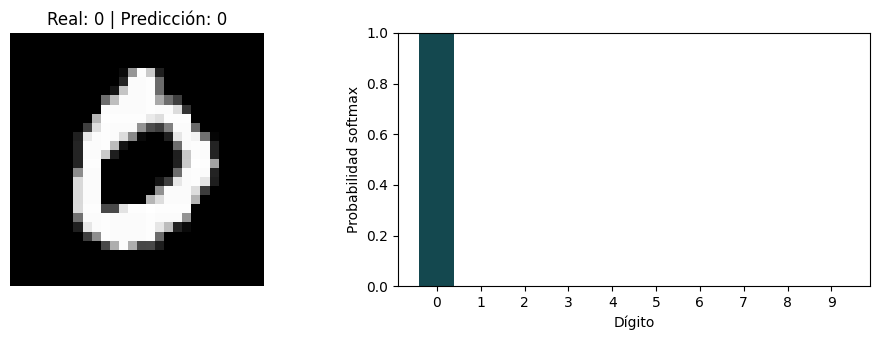

,digito,softmax
0,0,9.997806e-01
1,2,8.893054e-05
2,7,7.982272e-05
3,6,2.534955e-05
4,5,1.257935e-05
5,9,1.080902e-05
6,8,1.088157e-06
7,3,8.463085e-07
8,4,4.897903e-09
9,1,2.601163e-09


In [5]:
with np.load(BASE / "ejemplos_mnist.npz", allow_pickle=False) as datos:
    imagenes = datos["imagenes"].copy()
    etiquetas = datos["etiquetas"].copy()
assert imagenes.shape == (10, 28, 28)
assert etiquetas.shape == (10,)
assert imagenes.min() >= 0 and imagenes.max() <= 255

INDICE = 0  # Cambia este valor para explorar otro ejemplo.
imagen = imagenes[INDICE]
entrada_modelo = imagen.astype("float32")[None, ...]  # (1, 28, 28)
probabilidades = modelo(entrada_modelo, training=False).numpy()[0]
digito_predicho = int(np.argmax(probabilidades))
np.testing.assert_allclose(probabilidades.sum(), 1.0, atol=1e-5)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
ejes[0].imshow(imagen, cmap="gray", vmin=0, vmax=255)
ejes[0].set_title(f"Real: {etiquetas[INDICE]} | Predicción: {digito_predicho}")
ejes[0].axis("off")
ejes[1].bar(range(10), probabilidades, color="#14484F")
ejes[1].set(xticks=range(10), ylim=(0, 1), xlabel="Dígito", ylabel="Probabilidad softmax")
fig.tight_layout()
fig.savefig(SALIDA / "primera_prediccion.png", dpi=150)
plt.show()
display(pd.DataFrame({"digito": range(10), "softmax": probabilidades})
        .sort_values("softmax", ascending=False).reset_index(drop=True))


## 5. Predecir un lote de imágenes
El modelo puede procesar varias imágenes en una misma llamada.
Compara cada predicción con su etiqueta real y observa la puntuación softmax.

Una puntuación alta **no garantiza un acierto** ni debe interpretarse como una
probabilidad calibrada de que la respuesta sea correcta.


,digito_real,digito_predicho,softmax_maximo,acierto
0,0,0,0.999781,True
1,1,1,0.989736,True
2,2,2,0.997620,True
3,3,3,0.484360,True
4,4,4,0.990845,True
5,5,6,0.980715,False
6,6,6,0.944770,True
7,7,7,0.999292,True
8,8,8,0.981335,True
9,9,9,0.985028,True


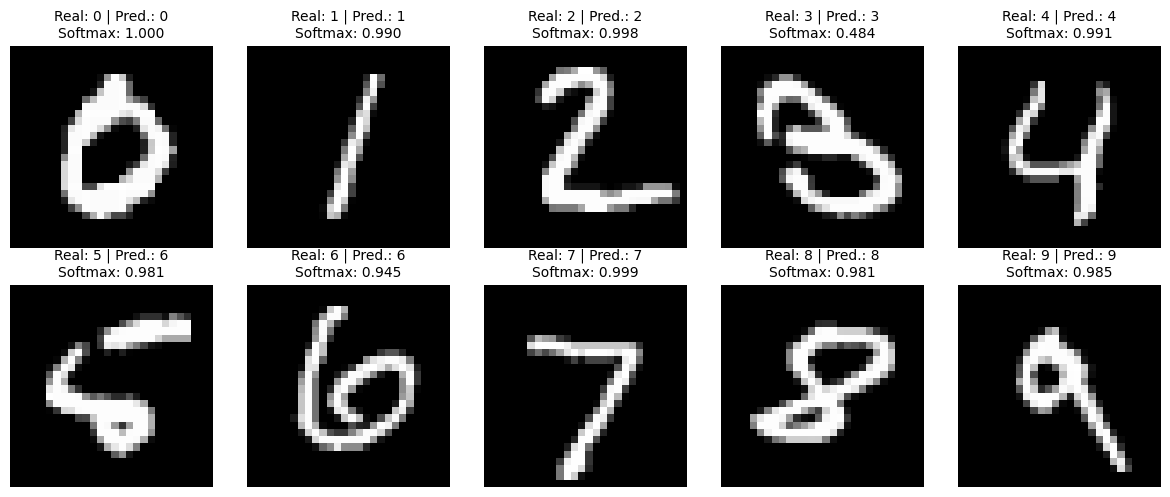

Aciertos en estos ejemplos: 9 de 10.


In [6]:
p_lote = modelo(imagenes.astype("float32"), training=False).numpy()
pred_lote = p_lote.argmax(axis=1)
tabla_mnist = pd.DataFrame({
    "digito_real": etiquetas, "digito_predicho": pred_lote,
    "softmax_maximo": p_lote.max(axis=1), "acierto": pred_lote == etiquetas
})
display(tabla_mnist)
tabla_mnist.to_csv(SALIDA / "predicciones_ejemplos_mnist.csv", index=False)

fig, ejes = plt.subplots(2, 5, figsize=(12, 5))
for i, eje in enumerate(ejes.flat):
    eje.imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
    eje.set_title(f"Real: {etiquetas[i]} | Pred.: {pred_lote[i]}\n"
                  f"Softmax: {p_lote[i].max():.3f}", fontsize=10)
    eje.axis("off")
fig.tight_layout()
fig.savefig(SALIDA / "predicciones_mnist.png", dpi=150)
plt.show()
print(f"Aciertos en estos ejemplos: {int((pred_lote == etiquetas).sum())} de {len(etiquetas)}.")


### Para interpretar
1. ¿El dígito real y el predicho coinciden en todos los ejemplos?
2. ¿Entre qué clases reparte el modelo su puntuación en el ejemplo más ambiguo?
3. ¿Por qué no debemos reemplazar la evaluación de las 10.000 imágenes de prueba
   del laboratorio 24 por el resultado de estos diez ejemplos?

**Respuestas:**


## 6. Preparar imágenes para la aplicación
La imagen que carga un usuario puede tener otro tamaño o fondo. Implementaremos
dos modos para que sea explícito cómo la adaptamos:

| Modo | Operaciones |
|---|---|
| **MNIST: conservar 28x28** | Verificar el tamaño y conservar los píxeles; es el modo de los PNG exportados en el laboratorio 24. |
| **Imagen propia: adaptar** | Convertir a grises, invertir si el trazo es oscuro, recortar alrededor del trazo, ajustar proporcionalmente a un máximo de 20 × 20 y centrar en un lienzo negro de 28 × 28. |

En ambos casos, el modelo recibe valores **0–255**; su capa `Rescaling` hace la normalización.
La adaptación de imágenes propias aproxima el formato visual de MNIST, pero
no reproduce exactamente su proceso original de adquisición y centrado.

Para una imagen propia utiliza **un solo dígito**, con trazos visibles, fondo
uniforme y sin objetos alrededor. Puedes dibujarlo en Paint y guardarlo como PNG.
Si usas trazo negro sobre blanco, activa **Invertir colores**.


In [7]:
MODO_MNIST = "MNIST: conservar 28x28"
MODO_PROPIO = "Imagen propia: adaptar"
def preparar_imagen(imagen_pil, modo=MODO_MNIST, invertir=False):
    """Devuelve una matriz uint8 de 28x28, sin dividir entre 255."""
    if imagen_pil is None:
        raise ValueError("Carga primero una imagen.")
    if modo not in (MODO_MNIST, MODO_PROPIO):
        raise ValueError("Selecciona uno de los dos modos disponibles.")
    imagen_pil = ImageOps.exif_transpose(imagen_pil).convert("RGBA")
    color_fondo = (255, 255, 255, 255) if invertir else (0, 0, 0, 255)
    fondo = Image.new("RGBA", imagen_pil.size, color_fondo)
    gris = Image.alpha_composite(fondo, imagen_pil).convert("L")
    if invertir:
        gris = ImageOps.invert(gris)
    pixeles = np.asarray(gris, dtype=np.uint8)
    if int(pixeles.max()) - int(pixeles.min()) < 10:
        raise ValueError("La imagen está vacía o tiene muy poco contraste.")

    if modo == MODO_MNIST:
        if gris.size != (28, 28):
            raise ValueError("Este modo requiere 28x28. Para otro tamaño usa 'Imagen propia: adaptar'.")
        return pixeles.copy()

    # Localizar el trazo claro sobre el fondo oscuro.
    umbral = max(20, 0.15 * float(pixeles.max()))
    filas, columnas = np.where(pixeles > umbral)
    if len(filas) == 0:
        raise ValueError("No se encontró un trazo visible. Revisa el fondo y la inversión.")
    recorte = gris.crop((int(columnas.min()), int(filas.min()),
                        int(columnas.max()) + 1, int(filas.max()) + 1))
    factor = 20 / max(recorte.size)
    tamano = tuple(max(1, round(v * factor)) for v in recorte.size)
    recorte = recorte.resize(tamano, Image.Resampling.LANCZOS)
    lienzo = Image.new("L", (28, 28), 0)
    lienzo.paste(recorte, ((28 - tamano[0]) // 2, (28 - tamano[1]) // 2))
    return np.asarray(lienzo, dtype=np.uint8).copy()

# El modo MNIST debe conservar exactamente los píxeles originales.
for img in imagenes:
    np.testing.assert_array_equal(preparar_imagen(Image.fromarray(img)), img)
print("Verificado: el modo MNIST conserva los píxeles de los diez ejemplos.")


Verificado: el modo MNIST conserva los píxeles de los diez ejemplos.


## 7. Observar el efecto del fondo y la preparación
Para ver el problema de forma controlada, invertiremos los colores de uno de
los ejemplos. No es una nueva imagen ni una nueva evaluación: es una demostración.

Compararemos la entrada original, la entrada invertida enviada sin corregir y
la entrada invertida después de corregirla. La tercera debe recuperar la primera.


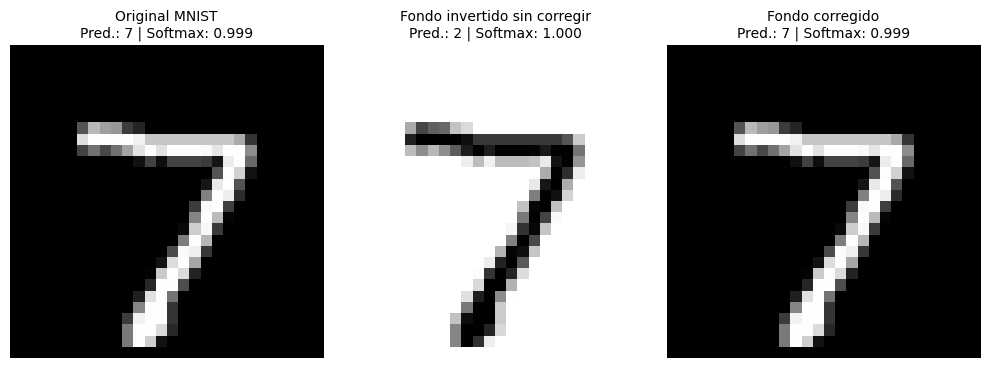

In [9]:
INDICE_DEMO = 7
original = imagenes[INDICE_DEMO]
invertida = 255 - original
corregida = preparar_imagen(Image.fromarray(invertida), MODO_MNIST, invertir=True)
np.testing.assert_array_equal(original, corregida)
variantes = np.stack([original, invertida, corregida])
p_variantes = modelo(variantes.astype("float32"), training=False).numpy()
nombres = ["Original MNIST", "Fondo invertido sin corregir", "Fondo corregido"]
fig, ejes = plt.subplots(1, 3, figsize=(10, 4))
for eje, img, p, nombre in zip(ejes, variantes, p_variantes, nombres):
    eje.imshow(img, cmap="gray", vmin=0, vmax=255)
    eje.set_title(f"{nombre}\nPred.: {p.argmax()} | Softmax: {p.max():.3f}", fontsize=10)
    eje.axis("off")
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig(SALIDA / "efecto_del_fondo.png", dpi=150, bbox_inches="tight", pad_inches=0.2)
plt.show()
np.testing.assert_allclose(p_variantes[0], p_variantes[2], atol=1e-6)


### Para interpretar
1. ¿Cambió la clase predicha, la distribución de probabilidades o ambas al invertir el fondo?
2. ¿Por qué corregir el fondo recupera la salida original?
3. ¿El modelo aprendió algo nuevo durante esta demostración? Justifica tu respuesta.

No es obligatorio que la clase predicha cambie: interpreta lo que muestre tu ejecución.

**Respuestas:**


## 8. Conectar el modelo con la interfaz
La siguiente función reúne tres pasos: **preparar la imagen → ejecutar el modelo
→ presentar la salida**. La red se cargó una sola vez; cada consulta reutiliza sus pesos.

La aplicación mostrará el dígito predicho, las tres clases con mayor puntuación
y la imagen de 28 × 28 que realmente recibió el modelo.
Registraremos las consultas exitosas y sus imágenes procesadas para analizarlas al final.

El control de imagen vacía evita algunos errores de entrada. **No comprueba que
el contenido sea un dígito:** ante una letra o un objeto, esta red también puede
asignar una de sus diez clases, incluso con una puntuación alta.


Dígito predicho: 0. Softmax máximo: 1.000. Esta puntuación no garantiza un acierto.


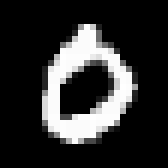

In [10]:
registro_consultas = []
IMAGENES_CONSULTADAS = SALIDA / "imagenes_procesadas"
IMAGENES_CONSULTADAS.mkdir(exist_ok=True)

def reconocer_digito(imagen_pil, modo, invertir):
    try:
        matriz = preparar_imagen(imagen_pil, modo, invertir)
    except ValueError as error:
        raise gr.Error(str(error)) from error
    entrada = matriz.astype("float32")[None, ...]
    p = modelo(entrada, training=False).numpy()[0]
    prediccion = int(p.argmax())
    numero = len(registro_consultas) + 1
    nombre_png = f"consulta_{numero:03d}.png"
    Image.fromarray(matriz).save(IMAGENES_CONSULTADAS / nombre_png)
    registro_consultas.append({
        "consulta": numero, "momento": datetime.now().isoformat(timespec="seconds"),
        "modo": modo, "invertir": bool(invertir), "digito_predicho": prediccion,
        "softmax_maximo": float(p.max()), "imagen_procesada": nombre_png,
        **{f"softmax_{d}": float(p[d]) for d in range(10)}
    })
    puntuaciones = {str(d): float(p[d]) for d in range(10)}
    mensaje = (f"Dígito predicho: {prediccion}. "
               f"Softmax máximo: {p.max():.3f}. Esta puntuación no garantiza un acierto.")
    return puntuaciones, Image.fromarray(matriz), mensaje
p_demo, imagen_demo, texto_demo = reconocer_digito(
    Image.fromarray(imagenes[0]), MODO_MNIST, False)
print(texto_demo)
display(imagen_demo.resize((168, 168), Image.Resampling.NEAREST))


## 9. Crear y abrir la interfaz
La primera celda construye la aplicación; la segunda la inicia.
Puedes seleccionar los ejemplos incluidos o cargar un archivo PNG/JPG propio.

1. Prueba primero un ejemplo de MNIST con su modo correspondiente.
2. Carga una imagen propia, cambia el modo y ajusta **Invertir colores** si corresponde.
3. Pulsa **Reconocer dígito** y revisa también la imagen procesada.

El nombre de cada ejemplo indica su **etiqueta real**, no una predicción garantizada.
Si el visor de Colab no aparece, abre el enlace que imprime la celda de lanzamiento.


In [12]:
EJEMPLOS_DIR = CARPETA / "ejemplos_interfaz"
EJEMPLOS_DIR.mkdir(exist_ok=True)
ejemplos_interfaz = []
for i, etiqueta in enumerate(etiquetas):
    ruta = EJEMPLOS_DIR / f"digito_real_{int(etiqueta)}.png"
    Image.fromarray(imagenes[i]).save(ruta)
    ejemplos_interfaz.append([str(ruta.resolve()), MODO_MNIST, False])

# Cerrar la instancia anterior si vuelves a ejecutar esta celda.
if "demo" in globals():
    demo.close()

with gr.Blocks(title="Laboratorio 25 | Reconocimiento de dígitos") as demo:
    gr.Markdown("# Reconocimiento de dígitos con MNIST\n"
                "Carga un solo dígito y revisa cómo lo recibe el modelo. "
                "Analítica de Datos — Universidad Cooperativa de Colombia.")
    with gr.Row():
        with gr.Column():
            entrada_imagen = gr.Image(type="pil", image_mode="RGBA", sources=["upload"],
                                       label="Imagen del dígito")
            modo_entrada = gr.Radio([MODO_MNIST, MODO_PROPIO], value=MODO_MNIST,
                                   label="Preparación de la imagen")
            invertir_colores = gr.Checkbox(value=False,
                label="Invertir colores: activar para trazo oscuro sobre fondo claro")
            boton = gr.Button("Reconocer dígito", variant="primary")
        with gr.Column():
            salida_clases = gr.Label(num_top_classes=3, label="Clases con mayor puntuación softmax")
            salida_imagen = gr.Image(type="pil", label="Entrada del modelo: 28 × 28", interactive=False)
            salida_texto = gr.Textbox(label="Resultado", interactive=False)
    gr.Examples(examples=ejemplos_interfaz,
                inputs=[entrada_imagen, modo_entrada, invertir_colores],
                label="Ejemplos de MNIST; después pulsa Reconocer dígito")
    boton.click(fn=reconocer_digito,
                inputs=[entrada_imagen, modo_entrada, invertir_colores],
                outputs=[salida_clases, salida_imagen, salida_texto],
                api_name="reconocer", concurrency_limit=1)
    gr.Markdown("La imagen procesada debe mostrar un trazo claro sobre fondo oscuro. "
                "La red solo conoce las clases 0–9; una puntuación alta no garantiza un acierto.")


In [13]:
# En Colab se necesita un enlace temporal para acceder a la aplicación.
# En Jupyter local se utiliza el servidor local.
demo.queue().launch(share=EN_COLAB, inline=True, debug=False,
                    allowed_paths=[str(EJEMPLOS_DIR.resolve())])

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://550f8d2d42737e07da.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Actividad: probar y explicar el comportamiento
Realiza estas pruebas con la interfaz. Anota lo que observas; no es necesario
que todas las predicciones sean correctas.

| Prueba | Entrada y ajuste | Qué comparar |
|---|---|---|
| A | Dos ejemplos incluidos de MNIST; modo MNIST | Clase real, predicción y puntuación. |
| B | Un dígito propio claro sobre negro; modo imagen propia | Si la imagen procesada conserva bien el trazo. |
| C | Un dígito propio negro sobre blanco; primero sin invertir y luego invirtiendo | El efecto del fondo sobre la entrada y la predicción. |
| D | Otro dígito propio con una forma de escritura diferente | Si la red reconoce esa escritura y dónde puede confundirse. |

Para las pruebas propias puedes guardar dibujos en PNG desde Paint.
La opción de inversión debe corresponder al fondo de la imagen; no la elijas
únicamente porque produzca la respuesta que esperas.

**Completa este registro en la celda Markdown:**

| Prueba | Dígito real | Predicción | Softmax máximo | Observación sobre la imagen procesada |
|---|---|---|---|---|
| A1 | | | | |
| A2 | | | | |
| B | | | | |
| C sin invertir | | | | |
| C invirtiendo | | | | |
| D | | | | |

**Análisis:**
1. ¿En cuáles pruebas acertó el modelo y en cuáles se equivocó?
2. ¿Qué cambió al preparar correctamente el fondo?
3. ¿Por qué un buen resultado con MNIST no garantiza reconocer cualquier fotografía?
4. ¿Qué componente cambiarías si la imagen llega recortada incorrectamente?
5. ¿Qué diferencia hay entre mostrar una predicción y volver a entrenar la red?

**Respuestas:**


## 11. Guardar las consultas y verificar que el modelo no cambió
Ejecuta esta celda **después de utilizar la interfaz**. El registro incluye la
comprobación inicial y las consultas exitosas de la aplicación.
No tiene etiquetas reales para las imágenes propias: por eso no calcula automáticamente
su exactitud. Esa comparación se hace con tu registro de la actividad.

También comprobaremos que los pesos siguen siendo iguales a los recuperados al cargar
el modelo. Inferir no actualiza los parámetros.


In [14]:
tabla_consultas = pd.DataFrame(registro_consultas)
display(tabla_consultas[["consulta", "modo", "invertir", "digito_predicho", "softmax_maximo"]])
tabla_consultas.to_csv(SALIDA / "consultas_interfaz.csv", index=False)

for inicial, actual in zip(pesos_al_cargar, modelo.get_weights()):
    np.testing.assert_array_equal(inicial, actual)
print("Verificado: las predicciones no modificaron los pesos del modelo.")

versiones = {nombre: importlib.metadata.version(nombre)
            for nombre in ["numpy", "pandas", "matplotlib", "Pillow", "gradio"]}
versiones["tensorflow"] = tf.__version__
resumen = {
    "laboratorio": 25, "dataset": "MNIST", "sesion": ID_SESION,
    "modelo": RUTA_MODELO.name, "seleccion_lab24": configuracion["seleccion"],
    "consultas_registradas": len(tabla_consultas), "versiones": versiones,
    "entrada_modelo": "(n, 28, 28), intensidades 0-255, Rescaling integrado",
    "reentrenamiento": False
}
(SALIDA / "resumen_laboratorio25.json").write_text(
    json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
(SALIDA / "requirements_lab25.txt").write_text(
    "\n".join(f"{nombre}=={version}" for nombre, version in versiones.items()) + "\n",
    encoding="utf-8")
RUTA_RESULTADOS = Path(shutil.make_archive(str(CARPETA / "Laboratorio_25_MNIST_resultados"),
                                         "zip", root_dir=SALIDA))
print("Resultados listos:", RUTA_RESULTADOS.name)


,consulta,modo,invertir,digito_predicho,softmax_maximo
0,1,MNIST: conservar 28x28,False,0,0.999781
1,2,MNIST: conservar 28x28,False,1,0.989737


Verificado: las predicciones no modificaron los pesos del modelo.
Resultados listos: Laboratorio_25_MNIST_resultados.zip


In [ ]:
if EN_COLAB:
    files.download(str(RUTA_RESULTADOS))
else:
    display(FileLink(str(RUTA_RESULTADOS)))


## 12. Conclusión del laboratorio
Redacta entre **cinco y ocho líneas** explicando:
- Qué modelo cargaste y de dónde proviene.
- Cómo debe llegar una imagen a la red y por qué no la dividimos otra vez entre 255.
- Qué observaste al usar imágenes propias.
- Qué limitaciones tiene esta demostración y qué aprendiste sobre inferencia.

Apoya tu conclusión en **dos pruebas concretas** de la actividad.

**Conclusión:**

---

**Conserva para revisión:**
1. Este notebook ejecutado, con tus respuestas y la tabla de observaciones.
2. El archivo `Laboratorio_25_MNIST_resultados.zip`.
3. El ZIP del laboratorio 24, que contiene el modelo para volver a iniciar la aplicación.

Para descargar el notebook con tus respuestas en Colab, utiliza **Archivo →
Descargar → Descargar .ipynb**. El ZIP de resultados no incluye tus respuestas Markdown.

La aplicación es temporal. En un despliegue permanente harían falta un servidor
disponible y tareas de mantenimiento y seguimiento del modelo.


## Al terminar: cerrar la aplicación
Deja `CERRAR_APLICACION = False` mientras estés haciendo las pruebas.
Cuando termines, cámbialo a `True` y ejecuta esta celda. Para abrirla de nuevo,
vuelve a ejecutar la celda de lanzamiento.


In [15]:
CERRAR_APLICACION = False
if CERRAR_APLICACION:
    demo.close()
    print("Aplicación cerrada.")
else:
    print("La aplicación continúa disponible mientras la sesión permanezca activa.")


La aplicación continúa disponible mientras la sesión permanezca activa.


## Si aparece un problema
| Situación | Qué hacer |
|---|---|
| No encuentro `modelo_mnist.keras` o faltan ejemplos | Vuelve a exportar y descargar el ZIP completo del laboratorio 24. |
| Falla la carga del modelo por una incompatibilidad de versiones | Revisa la versión de TensorFlow registrada en `configuracion_y_resultados.json` y utiliza un entorno compatible con el del laboratorio 24. No desactives `safe_mode` para intentar resolverlo. |
| El modo MNIST informa que la imagen no es 28 × 28 | Usa un PNG original del ZIP o cambia a **Imagen propia: adaptar**. |
| La imagen procesada tiene el fondo claro | Revisa la casilla **Invertir colores** y la imagen original. |
| El visor de Gradio no aparece | Abre el enlace temporal impreso por la celda de lanzamiento; comprueba que Colab sigue conectado. |
| No se puede crear el enlace temporal | Reintenta el lanzamiento cuando la conexión esté disponible. Las predicciones de los pasos 4–8 siguen pudiendo ejecutarse en el notebook. |
| La aplicación predice mal un dígito | Revisa la entrada procesada y registra el error. La preparación correcta no garantiza que el modelo acierte. |
| Hice más consultas después de descargar resultados | Repite las dos celdas del paso 11 para actualizar el ZIP. |

## Referencias técnicas
- [Keras: guardar y cargar modelos](https://keras.io/api/models/model_saving_apis/model_saving_and_loading/).
- [Gradio: componente Image](https://www.gradio.app/docs/gradio/image).
- [Gradio: Blocks y lanzamiento de aplicaciones](https://www.gradio.app/docs/gradio/blocks).
- [Gradio: compartir una aplicación](https://www.gradio.app/guides/sharing-your-app).

Las referencias documentan las APIs utilizadas. Las actividades y el flujo didáctico
se desarrollaron para esta sesión y continúan el laboratorio 24.
